In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_parquet("../data/processed/4FLG_ProcesadoFisico.parquet")
df

,CLASS1,BlazarDist,Variability_Index,Frac_Variability,SpectrumType_LogParabola,SpectrumType_PowerLaw,SpectrumType_PLSuperExpCutoff,Energy_Flux100,Flux1000,LP_Index,LP_SigCurv,PL_Index,Pivot_Energy,nuFnu_Band_0,nuFnu_Band_4,nuFnu_Band_6,nuFnu_Band_7,LP_beta,GLAT
0,bcu,1,28.915590,0.663905,0,1,0,1.369124e-12,1.215529e-10,2.114229,0.394362,2.155106,3218.100098,3.127429e-15,1.411101e-13,2.164999e-13,2.679954e-19,0.049796,-14.338059
1,bll,1,51.742390,0.429135,0,1,0,7.807578e-12,7.024454e-10,2.052470,1.283201,2.081634,2065.146729,2.657329e-16,1.268975e-12,9.279336e-13,2.075041e-13,0.037899,-67.305008
2,bll,1,9.374194,0.000000,0,1,0,1.312396e-12,1.177290e-10,2.118043,0.000000,2.108952,2869.263672,2.732577e-17,1.341425e-13,2.877950e-13,5.795491e-17,-0.010222,-60.491329
3,fsrq,1,1861.603394,1.088172,1,0,0,2.281995e-11,1.185480e-09,2.545461,7.548741,2.670351,340.919525,1.066274e-11,4.341892e-13,2.722669e-15,5.911620e-16,0.148902,-40.167652
4,bcu,1,25.609457,0.368921,1,0,0,3.260804e-12,3.126771e-10,1.580971,2.630329,1.781085,2729.530029,3.136423e-14,6.833589e-13,8.547137e-13,2.149872e-13,0.120901,-72.028549
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4763,bcu,1,18.010399,0.259739,1,0,0,1.354165e-12,1.427346e-10,1.577917,3.787348,1.752499,5153.450684,1.062581e-15,3.169375e-13,1.105479e-13,5.420474e-18,0.366866,-58.040924
4764,bll,1,14.498226,0.068273,0,1,0,4.093997e-12,3.582566e-10,1.924309,0.000000,1.928476,2930.842285,7.993894e-13,6.011633e-13,9.546973e-13,3.571405e-13,0.004414,-76.542862
4765,bcu,1,6.934350,0.000000,1,0,0,1.116031e-12,7.982052e-11,2.639918,3.037318,2.714450,717.048584,3.582740e-12,2.547993e-14,4.679423e-16,3.466486e-16,0.446554,-64.472755
4766,bcu,1,8.082824,0.000000,1,0,0,1.752340e-12,2.448128e-10,1.904424,2.774415,2.094933,1490.850708,1.431744e-17,3.939935e-13,1.071259e-13,1.637076e-20,0.185941,-74.919624


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score
from sklearn.preprocessing import StandardScaler


In [33]:
#Preparación y escalamiento de datos para el modelo de clasificación
from imblearn.over_sampling import SMOTE

smote = False

X_blazar = df.drop(columns=["CLASS1", "BlazarDist"])
y_blazar = df["BlazarDist"]
y_class = df["CLASS1"]

print("Numero de muestras por clase antes de aplicar SMOTE:")
print(y_blazar.value_counts())


sm = SMOTE(random_state=42)
if smote:
    X_blazar, y_blazar= sm.fit_resample(X_blazar, y_blazar)

print("Numero de muestras por clase después de aplicar SMOTE:")
print(y_blazar.value_counts())

X_train, X_test, y_train, y_test = train_test_split(X_blazar, y_blazar, test_size=0.2, random_state=42, stratify=y_blazar)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Numero de muestras por clase antes de aplicar SMOTE:
BlazarDist
1    3932
0     836
Name: count, dtype: int64
Numero de muestras por clase después de aplicar SMOTE:
BlazarDist
1    3932
0     836
Name: count, dtype: int64


ValueError: could not convert string to float: 'N'

In [ ]:
#Entrenar y evaluar modelo

classifier = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

              precision    recall  f1-score   support

           0       0.92      0.56      0.70       167
           1       0.91      0.99      0.95       787

    accuracy                           0.92       954
   macro avg       0.92      0.78      0.82       954
weighted avg       0.92      0.92      0.91       954

ROC AUC: 0.9306545739524763
Confussion Matrix:


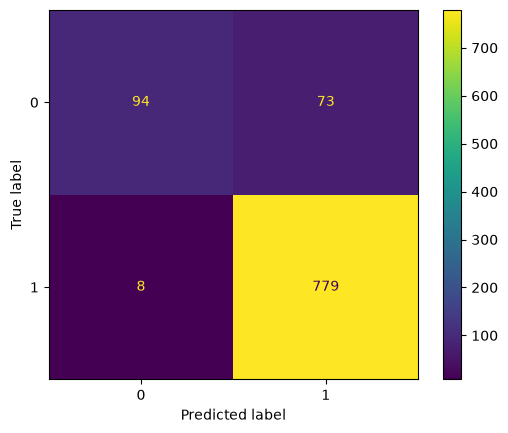

In [ ]:
print(classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, classifier.predict_proba(X_test)[:,1]))

print("Confussion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=classifier.classes_)
disp.plot()

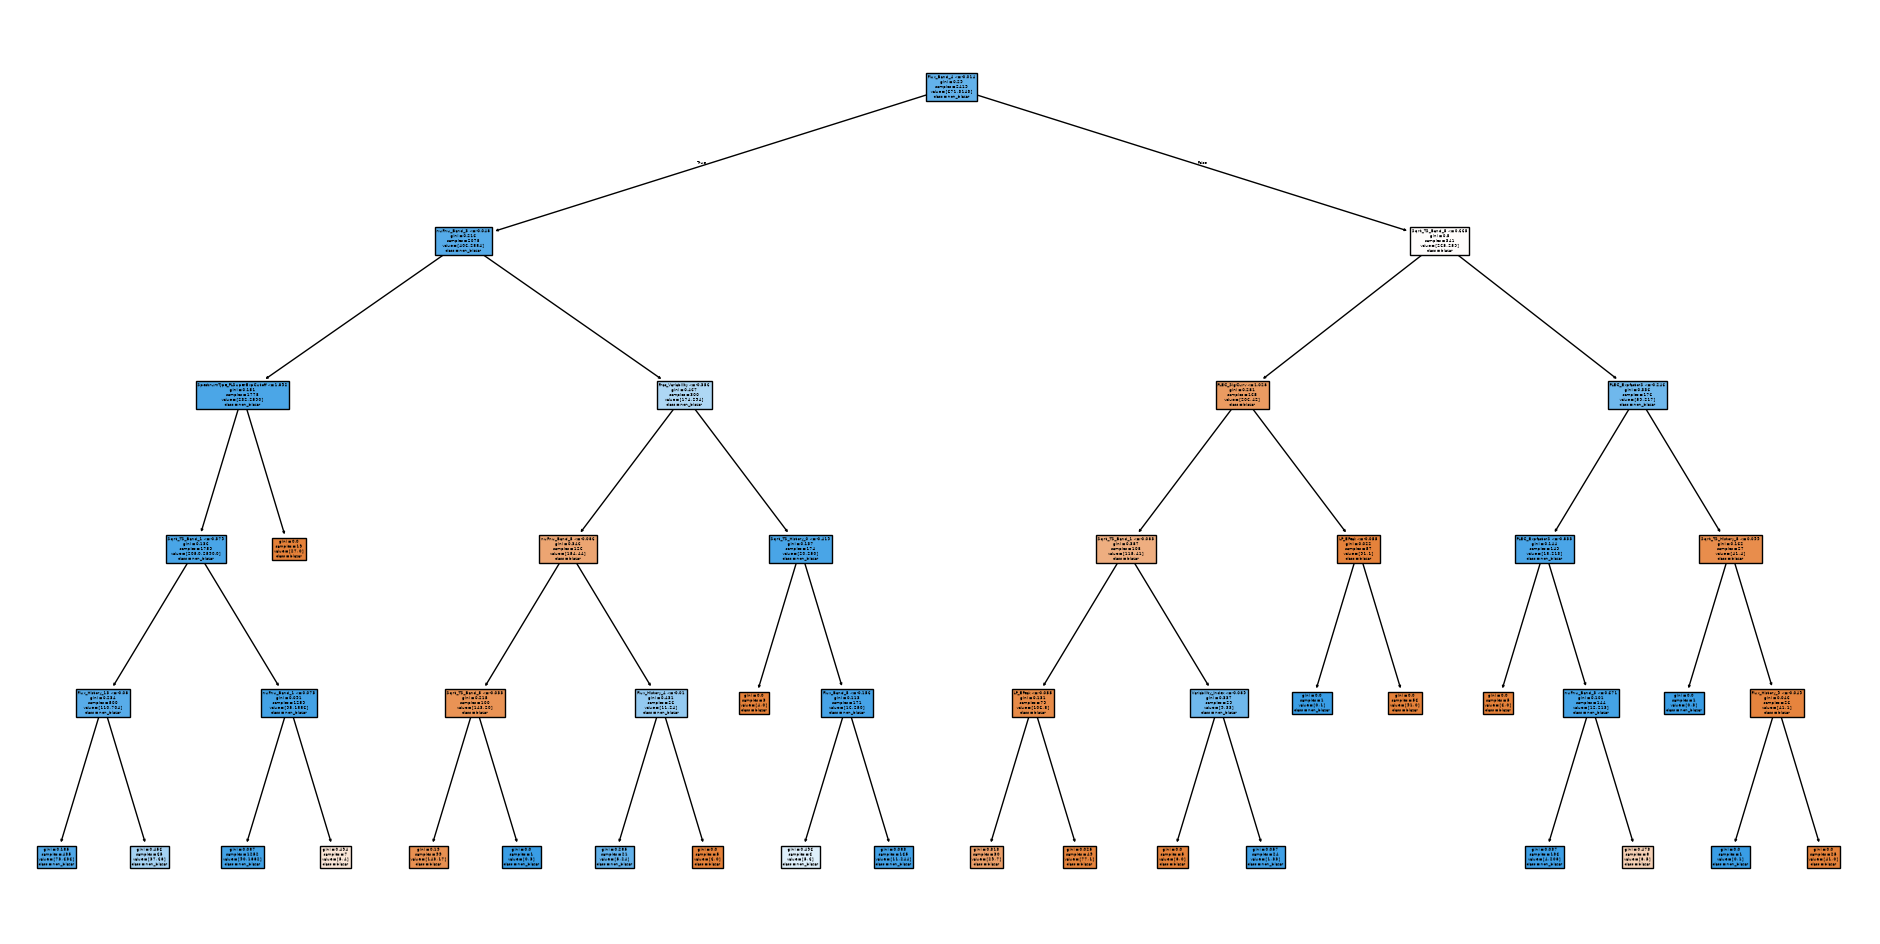

In [ ]:
from sklearn.tree import plot_tree

tree = classifier.estimators_[0]
plt.figure(figsize=(24,12))
plot_tree(tree, feature_names=X_blazar.columns, class_names=["blazar", "non_blazar"], filled=True)
plt.savefig("../visualization/mi_arbol_binary.png", bbox_inches="tight", dpi=300)

C:\Users\jonha\AppData\Local\Temp\ipykernel_22848\593920716.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


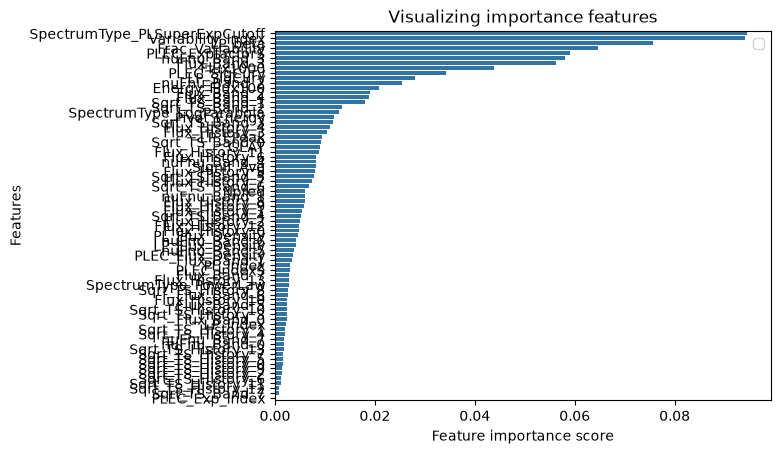

In [ ]:
feature_imp = pd.Series(classifier.feature_importances_,index=X_blazar.columns).sort_values(ascending=False)

sns.barplot(x=feature_imp, y=feature_imp.index)
plt.xlabel('Feature importance score')
plt.ylabel('Features')
plt.title("Visualizing importance features")
plt.legend()
plt.show()

#Clasificación de tipos

In [ ]:
smote = False

X_class = df.drop(columns=["CLASS1", "BlazarDist"])
y_class = df["CLASS1"]

X_blazar = df.drop(columns=["CLASS1", "BlazarDist"])
y_blazar = df["BlazarDist"]
y_class = df["CLASS1"]


print("Class distribution before SMOTE:")
print(y_class.value_counts())

sm = SMOTE(random_state=42)
if smote:
    X_class, y_class= sm.fit_resample(X_class, y_class)

print("Class distribution after SMOTE:")
print(y_class.value_counts())

X_train, X_test, y_train, y_test = train_test_split(X_class, y_class, test_size=0.2, random_state=42, stratify=y_class)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Class distribution before SMOTE:
CLASS1
bcu      1623
bll      1490
other     836
fsrq      819
Name: count, dtype: int64
Class distribution after SMOTE:
CLASS1
bcu      1623
bll      1490
other     836
fsrq      819
Name: count, dtype: int64


In [ ]:
#Entrenar y evaluar modelo

classifier = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

              precision    recall  f1-score   support

         bcu       0.55      0.72      0.62       325
         bll       0.74      0.67      0.71       298
        fsrq       0.71      0.61      0.66       164
       other       0.91      0.63      0.75       167

    accuracy                           0.67       954
   macro avg       0.73      0.66      0.68       954
weighted avg       0.70      0.67      0.68       954

Confussion Matrix:


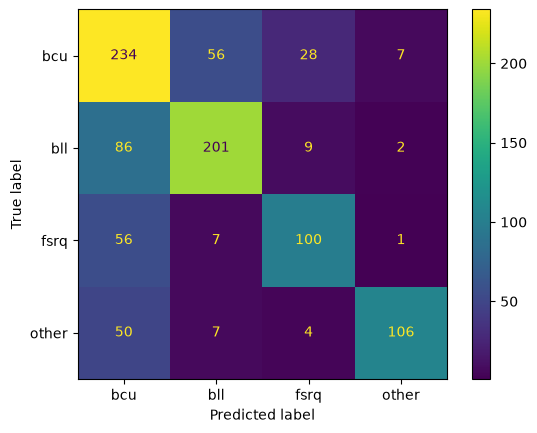

In [ ]:
print(classification_report(y_test, y_pred))

print("Confussion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=classifier.classes_)
disp.plot()

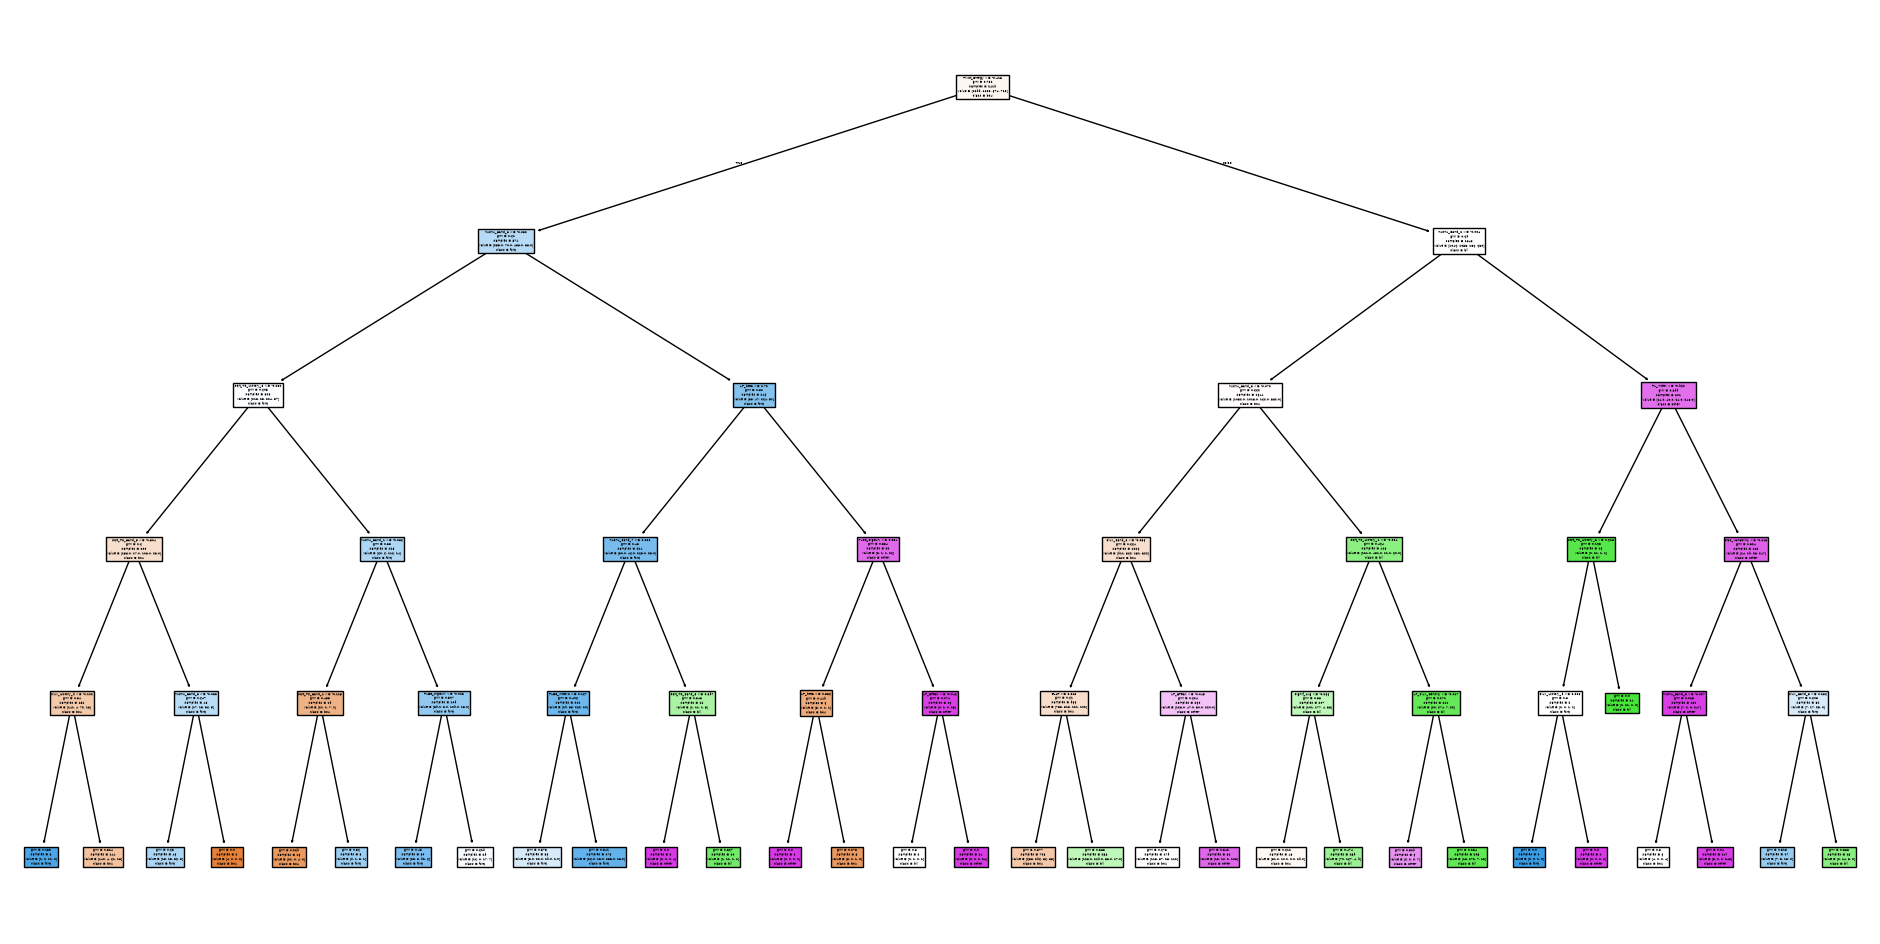

In [ ]:
from sklearn.tree import plot_tree

tree = classifier.estimators_[0]
plt.figure(figsize=(24,12))
plot_tree(tree, feature_names=X_class.columns, class_names=classifier.classes_, filled=True)
plt.savefig("../visualization/mi_arbol_multiclass.png", bbox_inches="tight", dpi=300)